# BABE SG2: Data Audit and Baseline Tests

This notebook tests the cleaned BABE SG2 binary task (`non-biased` = 0, `biased` = 1):

1. Audit missing values, duplicate texts, conflicting labels, and class balance.
2. Compare TF-IDF + Logistic Regression with TF-IDF + Linear SVM.
3. Run random, article-link-disjoint, and outlet-disjoint evaluations.
4. Save metrics to CSV and export the exact random split for a fair RoBERTa comparison.

**Important:** SG1 overlaps with SG2, so do not append SG1 as if it were new data. Ensure any comparison with RoBERTa uses the same held-out rows and preprocessing.


## 1. Install dependencies
Run once if needed.

In [1]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Load the cleaned dataset

The notebook expects text and binary labels, plus `news_link` and `outlet` columns for the grouped tests. Change `DATA_PATH` if needed.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

CANDIDATES = [
    Path("babe_cleaned.csv"),
    Path("../data/processed/babe_cleaned.csv"),
    Path("data/processed/babe_cleaned.csv"),
    Path("babe_cleaned.xlsx"),
    Path("../data/processed/babe_cleaned.xlsx"),
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    DATA_PATH = Path(input("Enter path to cleaned BABE SG2 CSV/XLSX: ").strip().strip('"'))
if not DATA_PATH.exists():
    raise FileNotFoundError(f"File not found: {DATA_PATH.resolve()}")

df_raw = pd.read_excel(DATA_PATH) if DATA_PATH.suffix.lower() in {".xlsx", ".xls"} else pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH.resolve(), "| shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
display(df_raw.head())

Loaded: C:\Users\ADMIN\Desktop\News Bias Detection\news-bias-detection\data\processed\babe_cleaned.csv | shape: (3669, 8)
Columns: ['text', 'news_link', 'outlet', 'topic', 'type', 'label_bias', 'label_opinion', 'biased_words']


,text,news_link,outlet,topic,type,label_bias,label_opinion,biased_words
0,"""Orange Is the New Black"" star Yael Stone is r...",https://www.foxnews.com/entertainment/australi...,Fox News,environment,right,Non-biased,Entirely factual,[]
1,"""We have one beautiful law,"" Trump recently sa...",https://www.alternet.org/2020/06/law-and-order...,Alternet,gun control,left,Biased,Somewhat factual but also opinionated,"['bizarre', 'characteristically']"
2,"...immigrants as criminals and eugenics, all o...",https://www.nbcnews.com/news/latino/after-step...,MSNBC,white-nationalism,left,Biased,Expresses writer’s opinion,"['criminals', 'fringe', 'extreme']"
3,...we sounded the alarm in the early months of...,https://www.alternet.org/2019/07/fox-news-has-...,Alternet,white-nationalism,left,Biased,Somewhat factual but also opinionated,[]
4,[Black Lives Matter] is essentially a non-fals...,http://feedproxy.google.com/~r/breitbart/~3/-v...,Breitbart,marriage-equality,NaN,Biased,Expresses writer’s opinion,['cult']


## 3. Normalize columns and labels
Review the detected columns and any unrecognized labels before trusting the results.

In [3]:
# Add your exact column names here if automatic detection doesn't find them.
def locate_column(columns, candidates):
    lookup = {str(c).strip().lower(): c for c in columns}
    for name in candidates:
        if name.lower() in lookup:
            return lookup[name.lower()]
    return None

text_col = locate_column(df_raw.columns, ["text", "sentence", "content", "article_text"])
label_col = locate_column(df_raw.columns, ["label_bias", "bias_label", "label bias", "label", "bias"])
article_col = locate_column(df_raw.columns, ["news_link", "news link", "article_url", "url", "link"])
outlet_col = locate_column(df_raw.columns, ["outlet", "source", "publisher", "news_outlet"])

if text_col is None or label_col is None:
    raise ValueError(f"Required text/label column not found. Detected text={text_col}, label={label_col}. Edit the candidates above.")

rename = {text_col: "text", label_col: "label_bias"}
if article_col is not None: rename[article_col] = "news_link"
if outlet_col is not None: rename[outlet_col] = "outlet"
df = df_raw.rename(columns=rename).copy()

def normalize_label(v):
    if pd.isna(v): return np.nan
    if isinstance(v, (int, np.integer, float, np.floating)) and v in (0, 1): return int(v)
    s = str(v).strip().lower().replace("_", "-")
    mapping = {"0": 0, "non-biased": 0, "non biased": 0, "nonbiased": 0, "unbiased": 0,
               "not biased": 0, "1": 1, "biased": 1}
    return mapping.get(s, np.nan)

df["label_bias"] = df["label_bias"].map(normalize_label)
df["text"] = df["text"].astype("string").str.strip()
df.loc[df["text"].eq(""), "text"] = pd.NA

print("Detected columns:", {"text": text_col, "label": label_col, "article": article_col, "outlet": outlet_col})
print("Missing text:", int(df["text"].isna().sum()))
print("Missing/unrecognized labels:", int(df["label_bias"].isna().sum()))
display(df["label_bias"].value_counts(dropna=False).rename_axis("label (0=non-biased, 1=biased)").to_frame("rows"))
unknown = df[df["label_bias"].isna()]
if len(unknown):
    print("Inspect unrecognized/missing labels:")
    display(unknown.head(10))

Detected columns: {'text': 'text', 'label': 'label_bias', 'article': 'news_link', 'outlet': 'outlet'}
Missing text: 0
Missing/unrecognized labels: 0


,rows
"label (0=non-biased, 1=biased)",
0,1862
1,1807


## 4. Data quality audit
Conflicting labels for identical text are excluded from the modeling frame; exact duplicate texts are reduced to one row.

In [4]:
valid = df.dropna(subset=["text", "label_bias"]).copy()
valid["label_bias"] = valid["label_bias"].astype(int)
duplicate_rows = int(valid.duplicated("text", keep=False).sum())
n_unique = int(valid["text"].nunique())
conflict_groups = valid.groupby("text")["label_bias"].nunique()
conflict_texts = conflict_groups[conflict_groups > 1].index
print(f"Valid rows: {len(valid):,}")
print(f"Rows in duplicate-text groups: {duplicate_rows:,}")
print(f"Unique exact texts: {n_unique:,}")
print(f"Conflicting text groups: {len(conflict_texts):,}")
print("Article link available:", "news_link" in valid.columns)
print("Outlet available:", "outlet" in valid.columns)
if len(conflict_texts):
    display(valid[valid["text"].isin(conflict_texts)][["text", "label_bias"]].head(20))

model_df = valid[~valid["text"].isin(conflict_texts)].drop_duplicates("text").reset_index(drop=True)
print("Rows after conservative cleanup:", len(model_df))
display(model_df["label_bias"].value_counts().sort_index().rename(index={0:"non-biased (0)", 1:"biased (1)"}).to_frame("count"))
display((model_df["label_bias"].value_counts(normalize=True).sort_index()*100).round(2).rename(index={0:"non-biased (0)", 1:"biased (1)"}).to_frame("percent"))

Valid rows: 3,669
Rows in duplicate-text groups: 0
Unique exact texts: 3,669
Conflicting text groups: 0
Article link available: True
Outlet available: True
Rows after conservative cleanup: 3669


,count
label_bias,
non-biased (0),1862
biased (1),1807


,percent
label_bias,
non-biased (0),50.75
biased (1),49.25


## 5. Models and evaluation helpers
Macro-F1 is a key metric because it weights both classes equally.

In [5]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
TEST_SIZE = 0.20

def build_models():
    return {
        "TF-IDF + Logistic Regression": Pipeline([
            ("tfidf", TfidfVectorizer(lowercase=True, strip_accents="unicode", ngram_range=(1, 2),
                                      min_df=2, max_features=100_000, sublinear_tf=True)),
            ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
        ]),
        "TF-IDF + Linear SVM": Pipeline([
            ("tfidf", TfidfVectorizer(lowercase=True, strip_accents="unicode", ngram_range=(1, 2),
                                      min_df=2, max_features=100_000, sublinear_tf=True)),
            ("clf", LinearSVC(class_weight="balanced", random_state=SEED)),
        ]),
    }

def evaluate(model, X_train, y_train, X_test, y_test, split_name, model_name):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    p, r, mf1, _ = precision_recall_fscore_support(y_test, pred, labels=[0, 1], average="macro", zero_division=0)
    result = {
        "split": split_name, "model": model_name,
        "n_train": len(y_train), "n_test": len(y_test),
        "accuracy": accuracy_score(y_test, pred),
        "macro_precision": p, "macro_recall": r, "macro_f1": mf1,
        "nonbiased_f1": f1_score(y_test, pred, pos_label=0, zero_division=0),
        "biased_f1": f1_score(y_test, pred, pos_label=1, zero_division=0),
    }
    print(f"\n{split_name} | {model_name}")
    print(classification_report(y_test, pred, labels=[0, 1], target_names=["non-biased", "biased"], digits=4, zero_division=0))
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["pred non-biased", "pred biased"],
                yticklabels=["actual non-biased", "actual biased"], ax=ax)
    ax.set_title(f"{split_name} — {model_name}")
    plt.tight_layout()
    plt.show()
    return result

def clean_group(s):
    s = s.astype("string").str.strip()
    return s.replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

## 6. Test A — Random stratified split
A standard baseline, but related sentences/articles or outlets may occur in both train and test.


Random stratified | TF-IDF + Logistic Regression
              precision    recall  f1-score   support

  non-biased     0.7551    0.6944    0.7235       373
      biased     0.7084    0.7673    0.7367       361

    accuracy                         0.7302       734
   macro avg     0.7318    0.7308    0.7301       734
weighted avg     0.7322    0.7302    0.7300       734



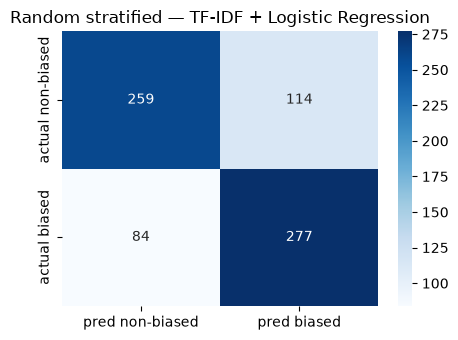


Random stratified | TF-IDF + Linear SVM
              precision    recall  f1-score   support

  non-biased     0.7384    0.6810    0.7085       373
      biased     0.6949    0.7507    0.7217       361

    accuracy                         0.7153       734
   macro avg     0.7166    0.7158    0.7151       734
weighted avg     0.7170    0.7153    0.7150       734



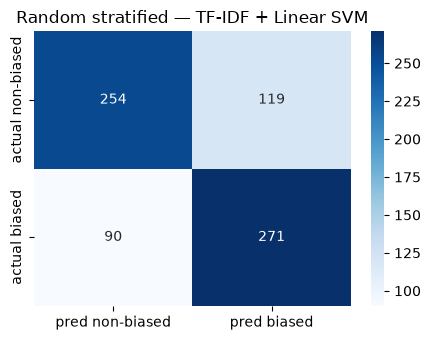

Train class proportions: {0: 0.507, 1: 0.493}
Test class proportions: {0: 0.508, 1: 0.492}


In [6]:
X = model_df["text"].astype(str)
y = model_df["label_bias"].astype(int)
indices = np.arange(len(model_df))
train_idx, test_idx = train_test_split(indices, test_size=TEST_SIZE, random_state=SEED, stratify=y)

results = []
for name, model in build_models().items():
    results.append(evaluate(model, X.iloc[train_idx], y.iloc[train_idx],
                            X.iloc[test_idx], y.iloc[test_idx], "Random stratified", name))

random_test_indices = test_idx.copy()
print("Train class proportions:", y.iloc[train_idx].value_counts(normalize=True).sort_index().round(3).to_dict())
print("Test class proportions:", y.iloc[test_idx].value_counts(normalize=True).sort_index().round(3).to_dict())

## 7. Test B — Article-link-disjoint split
No article link should appear in both train and test. Rows without article links are excluded from this split.

Rows with article links: 3,637; unique links: 2,095
Train/test rows: 2945 692
Train/test class proportions: {0: 0.511, 1: 0.489} {0: 0.49, 1: 0.51}

Article-link-disjoint | TF-IDF + Logistic Regression
              precision    recall  f1-score   support

  non-biased     0.7255    0.7640    0.7443       339
      biased     0.7612    0.7224    0.7413       353

    accuracy                         0.7428       692
   macro avg     0.7433    0.7432    0.7428       692
weighted avg     0.7437    0.7428    0.7427       692



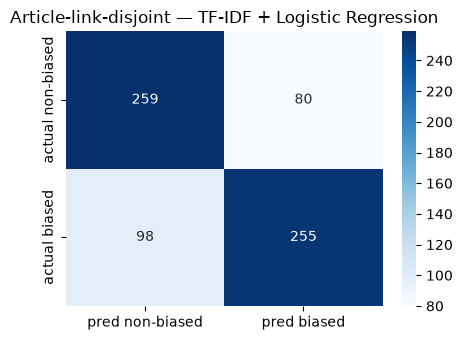


Article-link-disjoint | TF-IDF + Linear SVM
              precision    recall  f1-score   support

  non-biased     0.6965    0.7581    0.7260       339
      biased     0.7461    0.6827    0.7130       353

    accuracy                         0.7197       692
   macro avg     0.7213    0.7204    0.7195       692
weighted avg     0.7218    0.7197    0.7194       692



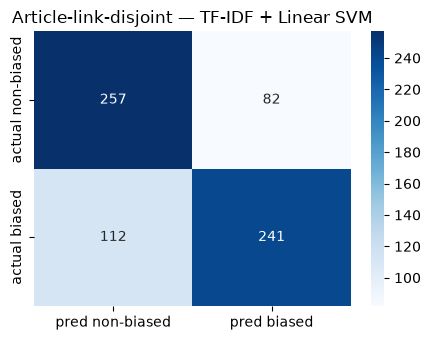

In [7]:
if "news_link" not in model_df.columns:
    print("SKIPPED: dataset has no news_link column.")
else:
    group_df = model_df.copy()
    group_df["group_key"] = clean_group(group_df["news_link"])
    group_df = group_df.dropna(subset=["group_key"]).reset_index(drop=True)
    print(f"Rows with article links: {len(group_df):,}; unique links: {group_df['group_key'].nunique():,}")
    if group_df["group_key"].nunique() < 2:
        print("SKIPPED: fewer than two distinct article links.")
    else:
        splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
        tr, te = next(splitter.split(group_df["text"], group_df["label_bias"], groups=group_df["group_key"]))
        train_df, test_df = group_df.iloc[tr], group_df.iloc[te]
        assert set(train_df["group_key"]).isdisjoint(set(test_df["group_key"]))
        print("Train/test rows:", len(train_df), len(test_df))
        print("Train/test class proportions:",
              train_df["label_bias"].value_counts(normalize=True).sort_index().round(3).to_dict(),
              test_df["label_bias"].value_counts(normalize=True).sort_index().round(3).to_dict())
        for name, model in build_models().items():
            results.append(evaluate(model, train_df["text"].astype(str), train_df["label_bias"].astype(int),
                                    test_df["text"].astype(str), test_df["label_bias"].astype(int),
                                    "Article-link-disjoint", name))

## 8. Test C — Outlet-disjoint split
No publisher/outlet should occur in both train and test. This evaluates transfer to unseen outlets and can be harder or less balanced.

Rows with outlets: 3,669; unique outlets: 11
Train/test rows: 1894 1775
Train/test outlets: 8 3
Train/test class proportions: {0: 0.428, 1: 0.572} {0: 0.593, 1: 0.407}

Outlet-disjoint | TF-IDF + Logistic Regression
              precision    recall  f1-score   support

  non-biased     0.7537    0.7300    0.7417      1052
      biased     0.6243    0.6528    0.6383       723

    accuracy                         0.6986      1775
   macro avg     0.6890    0.6914    0.6900      1775
weighted avg     0.7010    0.6986    0.6996      1775



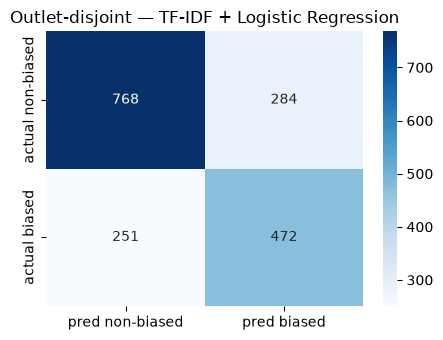


Outlet-disjoint | TF-IDF + Linear SVM
              precision    recall  f1-score   support

  non-biased     0.7479    0.6854    0.7153      1052
      biased     0.5919    0.6639    0.6258       723

    accuracy                         0.6766      1775
   macro avg     0.6699    0.6746    0.6705      1775
weighted avg     0.6844    0.6766    0.6788      1775



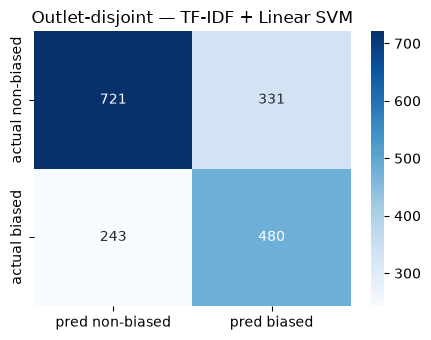

In [8]:
if "outlet" not in model_df.columns:
    print("SKIPPED: dataset has no outlet column.")
else:
    group_df = model_df.copy()
    group_df["group_key"] = clean_group(group_df["outlet"])
    group_df = group_df.dropna(subset=["group_key"]).reset_index(drop=True)
    print(f"Rows with outlets: {len(group_df):,}; unique outlets: {group_df['group_key'].nunique():,}")
    if group_df["group_key"].nunique() < 2:
        print("SKIPPED: fewer than two distinct outlets.")
    else:
        splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
        tr, te = next(splitter.split(group_df["text"], group_df["label_bias"], groups=group_df["group_key"]))
        train_df, test_df = group_df.iloc[tr], group_df.iloc[te]
        assert set(train_df["group_key"]).isdisjoint(set(test_df["group_key"]))
        print("Train/test rows:", len(train_df), len(test_df))
        print("Train/test outlets:", train_df["group_key"].nunique(), test_df["group_key"].nunique())
        print("Train/test class proportions:",
              train_df["label_bias"].value_counts(normalize=True).sort_index().round(3).to_dict(),
              test_df["label_bias"].value_counts(normalize=True).sort_index().round(3).to_dict())
        for name, model in build_models().items():
            results.append(evaluate(model, train_df["text"].astype(str), train_df["label_bias"].astype(int),
                                    test_df["text"].astype(str), test_df["label_bias"].astype(int),
                                    "Outlet-disjoint", name))

## 9. Compare and save results
Compare models within the same split. Do not treat scores from different split designs as directly equivalent.

In [9]:
results_df = pd.DataFrame(results).sort_values(["split", "macro_f1"], ascending=[True, False]).reset_index(drop=True)
display(results_df.style.format({c: "{:.4f}" for c in ["accuracy", "macro_precision", "macro_recall", "macro_f1", "nonbiased_f1", "biased_f1"]}))
output_path = Path("babe_baseline_comparison_results.csv")
results_df.to_csv(output_path, index=False)
print("Saved:", output_path.resolve())

,split,model,n_train,n_test,accuracy,macro_precision,macro_recall,macro_f1,nonbiased_f1,biased_f1
0,Article-link-disjoint,TF-IDF + Logistic Regression,2945,692,0.7428,0.7433,0.7432,0.7428,0.7443,0.7413
1,Article-link-disjoint,TF-IDF + Linear SVM,2945,692,0.7197,0.7213,0.7204,0.7195,0.7260,0.7130
2,Outlet-disjoint,TF-IDF + Logistic Regression,1894,1775,0.6986,0.6890,0.6914,0.6900,0.7417,0.6383
3,Outlet-disjoint,TF-IDF + Linear SVM,1894,1775,0.6766,0.6699,0.6746,0.6705,0.7153,0.6258
4,Random stratified,TF-IDF + Logistic Regression,2935,734,0.7302,0.7318,0.7308,0.7301,0.7235,0.7367
5,Random stratified,TF-IDF + Linear SVM,2935,734,0.7153,0.7166,0.7158,0.7151,0.7085,0.7217


Saved: C:\Users\ADMIN\Desktop\News Bias Detection\news-bias-detection\notebooks\babe_baseline_comparison_results.csv


## 10. Export exact random split for RoBERTa
Use this file to keep the train/test rows identical when comparing a transformer with these baselines.

In [10]:
export_df = model_df[["text", "label_bias"]].copy()
export_df["split"] = "train"
export_df.loc[random_test_indices, "split"] = "test"
split_path = Path("babe_random_split_for_roberta.csv")
export_df.to_csv(split_path, index=False)
print("Saved:", split_path.resolve())
display(export_df["split"].value_counts())

Saved: C:\Users\ADMIN\Desktop\News Bias Detection\news-bias-detection\notebooks\babe_random_split_for_roberta.csv


split
train    2935
test      734
Name: count, dtype: int64

## Interpretation guide

- **Random split:** ordinary baseline, but may be optimistic if related items appear across splits.
- **Article-link-disjoint:** tests generalization to unseen articles.
- **Outlet-disjoint:** tests generalization to unseen publishers; class balance may differ.
- **Macro-F1:** primary metric; also report accuracy and each class's F1.
- **Fair RoBERTa comparison:** use the exported random split (or create an equivalent grouped split for RoBERTa). Keep preprocessing and held-out examples identical.
- **Dataset expansion:** more records help only if their labels match this sentence-level binary task. SG1 overlaps with SG2 and should not be blindly appended.
